# WMC Practical Examination — Statement #08
## Effect of Channel Noise on Received Signal Quality (PathView / PathSim)

**Problem statement.** Using the PathView simulator, construct and simulate a basic communication system consisting of a transmitter, a noisy channel and a receiver.
1. Construct the model using SinusoidalSource, WhiteNoise, Adder and Scope, and connect the blocks appropriately.
2. Set WhiteNoise → standard_deviation to 0.0, 0.5 and 2.0 in separate simulation runs.
3. Observe the received waveform for each setting and complete the observation table with two columns (i) Noise standard deviation, (ii) Observed waveform and signal quality.

Draw the block diagram, complete the observation table and write a conclusion explaining how increasing noise affects the received signal.

---
**Aim:** To study the effect of additive white Gaussian noise (AWGN) in the channel on the quality of a received sinusoidal signal.

**Theory.** In the simplest channel model the received signal is **y(t) = x(t) + n(t)**, where x(t) = A·sin(2πft) is the transmitted signal and n(t) is white Gaussian noise of zero mean and standard deviation σ. The signal power is A²/2 and the noise power is σ², so the signal-to-noise ratio is **SNR = 10·log₁₀(A² / 2σ²) dB**. As σ grows the SNR falls and the received waveform departs further from the transmitted one.

## Building the same model in the PathView GUI
1. Open **PathView** (the graphical editor of PathSim) and start a new model.
2. From the block library drag in **SinusoidalSource** (transmitter), **WhiteNoise** (channel noise), **Adder** (channel) and **Scope** (receiver display).
3. Connect: `SinusoidalSource → Adder (input 1)`, `WhiteNoise → Adder (input 2)`, `Adder → Scope (input 2)`. Optionally also connect `SinusoidalSource → Scope (input 1)` so the clean transmitted signal is shown for comparison.
4. Block parameters: SinusoidalSource → `frequency = 2`, `amplitude = 1`; Adder → default (`+ +`); Scope → default.
5. Simulation settings: step size `dt = 0.002`, duration `2` s.
6. Set **WhiteNoise → standard_deviation** to **0.0**, **0.5** and **2.0** and press **Run** for each value, recording what the Scope shows.

       SNR = 10.log10(signal power/noise power)

       signal power = (amplitude^2) / 2

       noise power = sigma^2

The Python cells below use the **PathSim** library — the simulation engine that PathView runs — with exactly these blocks and parameters, so the waveforms below are what PathView's Scope displays (noise samples are random, so individual spikes differ from run to run, but the overall picture is the same).



## Simulation setup (imports, parameters and the PathSim model)

In [1]:
# If PathSim is not installed on your machine, uncomment and run once:
# %pip install pathsim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
from pathsim import Simulation, Connection
from pathsim.blocks import SinusoidalSource, WhiteNoise, Adder, Scope

FREQ, AMP = 2.0, 1.0        # transmitted sine: 2 Hz, amplitude 1 V
DT, T_END = 0.002, 2.0      # step size and simulation time (s)
NOISE_LEVELS = [0.0, 0.5, 2.0]

def run_channel(sigma, seed=7):
    """Tx (SinusoidalSource) -> Channel (Adder + WhiteNoise) -> Rx (Scope)."""
    tx    = SinusoidalSource(frequency=FREQ, amplitude=AMP)
    noise = WhiteNoise(standard_deviation=sigma, seed=seed)
    add   = Adder()
    scope = Scope(labels=["Transmitted", "Received"])
    sim = Simulation(
        blocks=[tx, noise, add, scope],
        connections=[
            Connection(tx, add[0], scope[0]),   # Tx -> channel and Tx -> scope ch0
            Connection(noise, add[1]),          # noise -> channel
            Connection(add, scope[1]),          # channel output -> receiver scope ch1
        ],
        dt=DT, log=False,
    )
    sim.run(T_END)
    t, data = scope.read()
    return np.asarray(t), np.asarray(data[0]), np.asarray(data[1])

runs = {s: run_channel(s) for s in NOISE_LEVELS}
print("Simulations completed for standard_deviation =", NOISE_LEVELS)

Simulations completed for standard_deviation = [0.0, 0.5, 2.0]


## Block diagram        

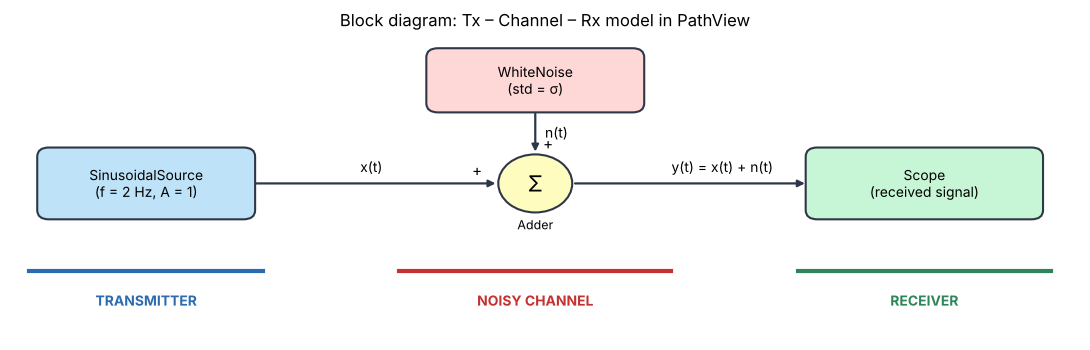

In [ ]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 4); ax.axis("off")

def blk(x, y, w, h, txt, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec="#2d3748", lw=1.5))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=10)

def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#2d3748"))

blk(0.3, 1.6, 2.2, 0.9, "SinusoidalSource\n(f = 2 Hz, A = 1)", "#bee3f8")
blk(4.3, 3.0, 2.2, 0.8, "WhiteNoise\n(std = σ)", "#fed7d7")
ax.add_patch(plt.Circle((5.4, 2.05), 0.38, fc="#fefcbf", ec="#2d3748", lw=1.5))
ax.text(5.4, 2.05, "Σ", ha="center", va="center", fontsize=16)
ax.text(5.4, 1.45, "Adder", ha="center", fontsize=9)
blk(8.2, 1.6, 2.4, 0.9, "Scope\n(received signal)", "#c6f6d5")
arrow(2.5, 2.05, 5.02, 2.05); ax.text(4.75, 2.15, "+", fontsize=11)
arrow(5.4, 3.0, 5.4, 2.43); ax.text(5.48, 2.5, "+", fontsize=11)
arrow(5.78, 2.05, 8.2, 2.05)
ax.text(3.6, 2.2, "x(t)", fontsize=10); ax.text(6.8, 2.2, "y(t) = x(t) + n(t)", fontsize=10)
ax.text(5.5, 2.65, "n(t)", fontsize=10)
for x0, x1, lab, col in [(0.2, 2.6, "TRANSMITTER", "#2b6cb0"), (4.0, 6.8, "NOISY CHANNEL", "#c53030"), (8.1, 10.7, "RECEIVER", "#2f855a")]:
    ax.plot([x0, x1], [0.9, 0.9], color=col, lw=3); ax.text((x0 + x1) / 2, 0.45, lab, ha="center", color=col, fontweight="bold")
ax.set_title("Block diagram: Tx – Channel – Rx model in PathView", fontsize=12)
plt.tight_layout(); plt.show()

## Received waveforms

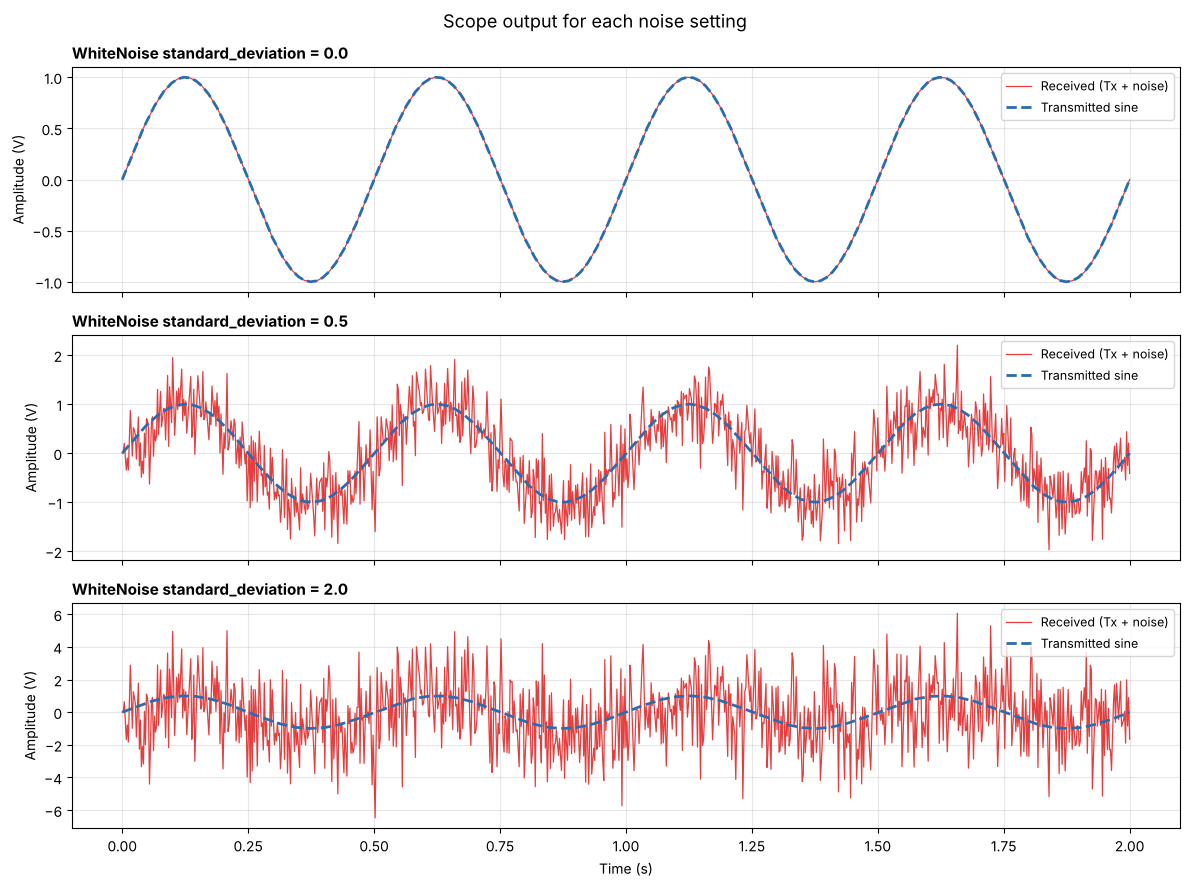

In [3]:
fig, axes = plt.subplots(len(NOISE_LEVELS), 1, figsize=(12, 3.0 * len(NOISE_LEVELS)), sharex=True)
for ax, s in zip(axes, NOISE_LEVELS):
    t, x, y = runs[s]
    ax.plot(t, y, color="#e53e3e", lw=0.9, label="Received (Tx + noise)")
    ax.plot(t, x, color="#2b6cb0", lw=2, ls="--", label="Transmitted sine")
    ax.set_title(f"WhiteNoise standard_deviation = {s}", loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("Amplitude (V)"); ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=9)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Scope output for each noise setting", fontsize=13)
plt.tight_layout(); plt.show()

In [4]:
rows = []
P_signal = AMP**2 / 2
for s in NOISE_LEVELS:
    t, x, y = runs[s]
    n = y - x
    p_noise = np.mean(n**2)
    snr = np.inf if p_noise == 0 else 10 * np.log10(P_signal / p_noise)
    rho = np.corrcoef(x, y)[0, 1]
    rows.append({"Noise std (σ)": s, "Measured noise std": round(float(np.std(n)), 3),
                 "SNR (dB)": "∞ (no noise)" if np.isinf(snr) else round(float(snr), 2),
                 "Peak |received| (V)": round(float(np.max(np.abs(y))), 2),
                 "Correlation Tx↔Rx": round(float(rho), 3)})
metrics = pd.DataFrame(rows)
display(Markdown("### Measured channel quality (computed from the simulated waveforms)"))
display(metrics.style.hide(axis="index").format(precision=3))

### Measured channel quality (computed from the simulated waveforms)

Noise std (σ),Measured noise std,SNR (dB),Peak |received| (V),Correlation Tx↔Rx
0.000,0.000,∞ (no noise),1.000,1.000
0.500,0.470,3.510,2.200,0.826
2.000,1.882,-8.530,6.480,0.321


## Observation table

In [5]:
quality = {
    0.0: "Clean, smooth sine wave identical to the transmitted signal; no distortion. Signal quality: EXCELLENT (SNR = ∞).",
    0.5: "Sine wave clearly visible but with small random fluctuations (fuzzy edges) riding on it; peaks and zero-crossings still identifiable. Signal quality: GOOD / MODERATE.",
    2.0: "Waveform dominated by large random spikes, several times the sine amplitude; the sinusoidal shape is buried and hard to see. Signal quality: POOR.",
}
obs = pd.DataFrame({"(i) Noise standard deviation": NOISE_LEVELS,
                    "(ii) Observed waveform and signal quality": [quality[s] + ("" if s == 0 else f"  [measured SNR ≈ {metrics.loc[i, 'SNR (dB)']} dB]")
                                                                  for i, s in enumerate(NOISE_LEVELS)]})
display(obs.style.hide(axis="index").format(precision=1).set_properties(**{"text-align": "left"}))

(i) Noise standard deviation,(ii) Observed waveform and signal quality
0.0,"Clean, smooth sine wave identical to the transmitted signal; no distortion. Signal quality: EXCELLENT (SNR = ∞)."
0.5,Sine wave clearly visible but with small random fluctuations (fuzzy edges) riding on it; peaks and zero-crossings still identifiable. Signal quality: GOOD / MODERATE. [measured SNR ≈ 3.51 dB]
2.0,"Waveform dominated by large random spikes, several times the sine amplitude; the sinusoidal shape is buried and hard to see. Signal quality: POOR. [measured SNR ≈ -8.53 dB]"


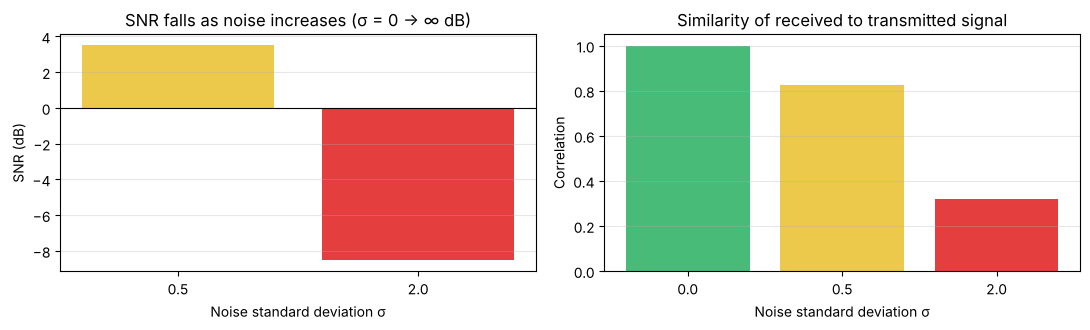

In [6]:
snrs = [np.nan if isinstance(v, str) else v for v in metrics["SNR (dB)"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar([str(s) for s in NOISE_LEVELS[1:]], snrs[1:], color=["#ecc94b", "#e53e3e"])
ax[0].set_xlabel("Noise standard deviation σ"); ax[0].set_ylabel("SNR (dB)"); ax[0].set_title("SNR falls as noise increases (σ = 0 → ∞ dB)")
ax[0].axhline(0, color="k", lw=0.8)
ax[1].bar([str(s) for s in NOISE_LEVELS], metrics["Correlation Tx↔Rx"], color=["#48bb78", "#ecc94b", "#e53e3e"])
ax[1].set_ylim(0, 1.05); ax[1].set_xlabel("Noise standard deviation σ"); ax[1].set_ylabel("Correlation"); ax[1].set_title("Similarity of received to transmitted signal")
for a in ax: a.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## Conclusion
- With **σ = 0.0** the channel is ideal: the received signal is an exact copy of the transmitted sine (SNR = ∞, correlation = 1).
- With **σ = 0.5** the sine is still clearly recognisable, but random fluctuations are superimposed on it; the SNR is about **3 dB** in theory (signal power 0.5 vs noise power 0.25; ≈ 3.5 dB measured in this run).
- With **σ = 2.0** the noise power (4) is eight times the signal power (0.5), the SNR drops to about **−9 dB** (≈ −8.5 dB measured), and the sine wave is almost completely masked by random spikes.

**Increasing the noise standard deviation increases the noise power (σ²), lowers the SNR and the correlation between transmitted and received signals, and therefore degrades the received signal quality** — first as visible fuzz on the waveform and finally as complete loss of the waveform shape. In a real link this means more bit errors, which is why receivers use filtering, error-control coding and higher transmit power to keep the SNR high.